In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv('/Users/manishgrewal/python projects/mlprojects/notebook/data/stud.csv')

In [3]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.isnull().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [8]:
# print('Categories in "gender" variable:',end="")
# print(df['gender'].unique())

# print('Categories in race_ethnicity :',end="")
# print(df['race_ethnicity'].unique())

# print('Categories in parental_level_of_education:',end="")
# print(df['parental_level_of_education'].unique())

# print('Categories in lunch:',end="")
# print(df['lunch'].unique())

# print('Categories in test_preparation_course:',end="")
# print(df['test_preparation_course'].unique())

In [9]:
df.columns

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='str')

In [10]:
columns=['gender','race_ethnicity','parental_level_of_education','lunch','test_preparation_course']

In [11]:
for column in columns:
    print(f"Categories in {column}: {df[column].unique()}")

Categories in gender: <StringArray>
['female', 'male']
Length: 2, dtype: str
Categories in race_ethnicity: <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in parental_level_of_education: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in lunch: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in test_preparation_course: <StringArray>
['none', 'completed']
Length: 2, dtype: str


In [12]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [14]:
numerical_Columns=df.select_dtypes(include=np.number).columns.tolist()
Categorical_Columns=df.select_dtypes(exclude=np.number).columns.tolist()

print("we have {} numerical_columns{}:".format(len(numerical_Columns),numerical_Columns))
print("we have {} Categorical_Columns{}:".format(len(Categorical_Columns),Categorical_Columns))

we have 3 numerical_columns['math_score', 'reading_score', 'writing_score']:
we have 5 Categorical_Columns['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']:


In [15]:
df["Total_score"]=df['math_score']+df['reading_score']+df['writing_score']
df["average"]=df["Total_score"]/3

In [16]:
reading_full = (df["reading_score"] == 100).sum()
writing_full = (df["writing_score"] == 100).sum()
math_full = (df["math_score"] == 100).sum()

In [17]:
print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 7
Number of students with full marks in Writing: 14
Number of students with full marks in Reading: 17


In [18]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 4
Number of students with less than 20 marks in Writing: 3
Number of students with less than 20 marks in Reading: 1


<Axes: xlabel='average', ylabel='Count'>

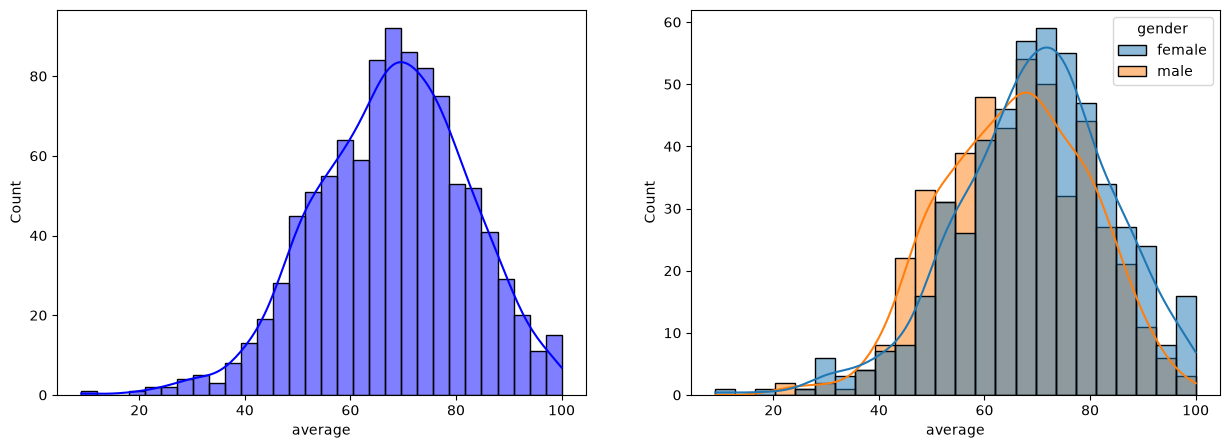

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plt.subplot(121)
sns.histplot(data=df, x=df['average'], bins=30, kde=True, color='blue')
plt.subplot(122)
sns.histplot(data=df, x=df['average'],kde=True,hue='gender')

<Axes: xlabel='Total_score', ylabel='Count'>

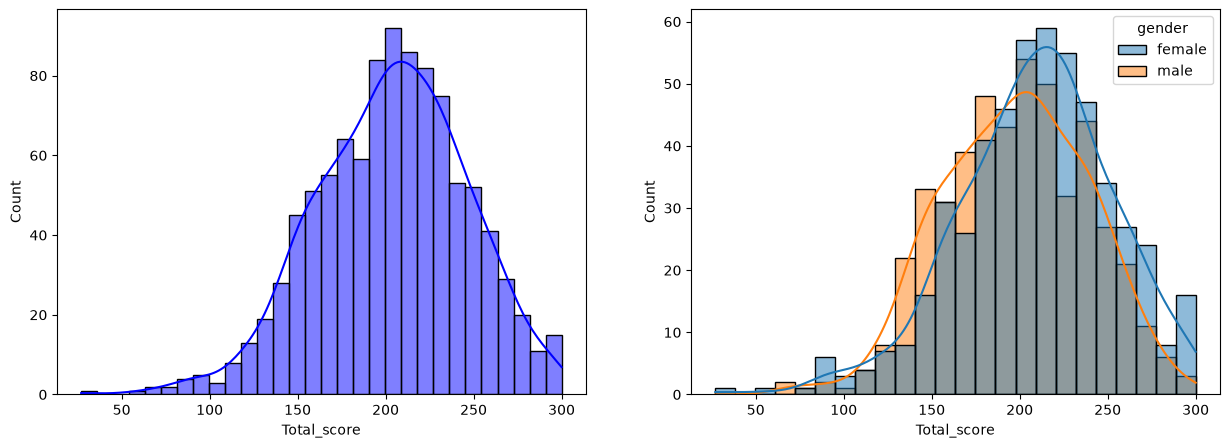

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plt.subplot(121)
sns.histplot(data=df, x='Total_score', bins=30, kde=True, color='blue')
plt.subplot(122)
sns.histplot(data=df, x='Total_score',kde=True,hue='gender')